# 01 · Exploratory Data Analysis (EDA)

Dataset: [`winvoker/turkish-sentiment-analysis-dataset`](https://huggingface.co/datasets/winvoker/turkish-sentiment-analysis-dataset)

Goal: understand the data before building a model. Are the classes balanced? How long are the texts? Is there anything in the data that could mislead a model?

Note: the label `Notr` is the dataset's spelling of **Neutral**.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data import download_raw, clean
sns.set_theme(style='whitegrid')
raw_train, raw_test = download_raw()
print('Raw size   -> train:', raw_train.shape, ' test:', raw_test.shape)
train, test = clean(raw_train), clean(raw_test)
print('Clean size -> train:', train.shape, ' test:', test.shape)
train.head()

Raw size   -> train: (440679, 3)  test: (48965, 3)


Clean size -> train: (439474, 3)  test: (48940, 3)


,text,label,dataset
0,ürünü hepsiburadadan alalı 3 hafta oldu. orjin...,Positive,urun_yorumlari
1,"ürünlerden çok memnunum, kesinlikle herkese ta...",Positive,urun_yorumlari
2,"hızlı kargo, temiz alışveriş.teşekkür ederim.",Positive,urun_yorumlari
3,Çünkü aranan tapınak bu bölgededir .,Notr,wiki
4,bu telefonu başlıca alma nedenlerim ise elimde...,Positive,urun_yorumlari


## 1. Class distribution
With imbalanced classes **accuracy is misleading**: if 70% of the data is one class, a model that always predicts that class gets 70% accuracy. That's why we also report **macro F1** (the unweighted mean of per-class F1 scores).

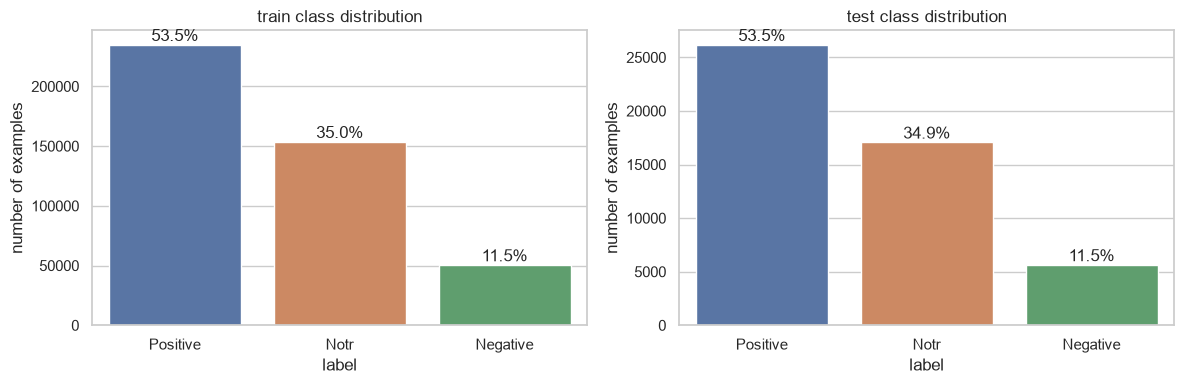

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (name, df) in zip(ax, [('train', train), ('test', test)]):
    vc = df['label'].value_counts()
    sns.barplot(x=vc.index, y=vc.values, ax=a, hue=vc.index, legend=False)
    a.set_title(f'{name} class distribution'); a.set_ylabel('number of examples')
    for i, v in enumerate(vc.values): a.text(i, v, f'{100*v/len(df):.1f}%', ha='center', va='bottom')
plt.tight_layout(); plt.show()

## 2. Where do the texts come from? (`dataset` column)
The dataset combines several sources: product reviews (`urun_yorumlari`), store reviews (`magaza_yorumlari`), movie reviews (`HUMIR`), tweets (`tweet-pn`), Wikipedia sentences (`wiki`) and filler text (`random`). Let's look at how source and label relate.

In [3]:
pd.crosstab(train['dataset'], train['label'], margins=True)

label,Negative,Notr,Positive,All
dataset,,,,
HUMIR,29089,0,28992,58081
magaza_yorumlari,3798,0,3756,7554
random,0,460,0,460
tweet-pn,4440,0,5497,9937
urun_yorumlari,13298,0,196780,210078
wiki,0,153364,0,153364
All,50625,153824,235025,439474


**Key observation:** the `Notr` (Neutral) class comes entirely from `wiki` (encyclopedia sentences) and `random`. No review or tweet is labeled Neutral. So instead of learning "neutral sentiment", a model can learn "is this an encyclopedia sentence?". This is called **shortcut learning**. The test set has the same structure, so scores look high, but in real use (e.g. a neutral product review) the model may fail. We keep this in mind when interpreting the results and also report a separate F1 for the Negative and Positive classes.

In [4]:
for src in train['dataset'].unique():
    print(f'--- {src} ---')
    for t in train[train['dataset'] == src].sample(min(3, (train['dataset'] == src).sum()), random_state=0)['text']: print('  •', t[:150])

--- urun_yorumlari ---
  • merhabalar ben bu parfümü yaklaşık olarak 10 ay önce bir kız arkadaşıma hediye almıştım ve gayet de memnun kaldım parfümün kokusu çok hoş ve kalıcı ol
  • kredi kartlığimda saklıyorum, her işe yarıyor, cepte i̇sviçre çakısı gibi şişkinlik yapmıyor. yoğun ilgi yaratiyor, 5 adet daha siparis verdim, beğeni
  • kısa sürede şarj olan telefonun şarjı daha kısa sürede bitti. hem büyük hem ağır. büyüklüğünü göze alıp aynı boyutta performans bekleyenlere şimdiden 
--- wiki ---
  • Sosyal Bilimler Enstitüsü İngiliz Dili ve İstanbul Üniversitesi Edebiyat Bölümü profesörüdür .
  • İkinci şans turunda elenmiştir .
  • Bölgede narenciye yetişmektedir .
--- HUMIR ---
  • hayatım filmlerinden biridir.kaç defa izlediğimi bilmiyorum ama şu anda bir kez daha izlerim.russell yine müthiş...bu filme 5 oscar vrerek cimrilik ya
  • bence korku filmi kültürü olanlar için vasat bi sinemadı.arkadaslarım begendi ama ben pek begenEmedim.bence testere türünden korku filmlerine gitmek k
 

## 3. Text lengths
Does BERT's `max_length=128` token limit cover most texts?

label          Negative      Notr  Positive
n_chars count   50625.0  153824.0  235025.0
        mean      264.2      58.4     166.3
        std       392.3      22.5     179.3
        min         1.0       1.0       1.0
        25%        79.0      42.0      66.0
        50%       158.0      56.0     133.0
        75%       291.0      73.0     207.0
        max     16828.0     598.0   12058.0
n_words count   50625.0  153824.0  235025.0
        mean       37.0       8.7      23.3
        std        54.2       3.0      24.9
        min         1.0       1.0       1.0
        25%        11.0       6.0       9.0
        50%        22.0       8.0      19.0
        75%        41.0      11.0      29.0
        max      2329.0      92.0    2724.0


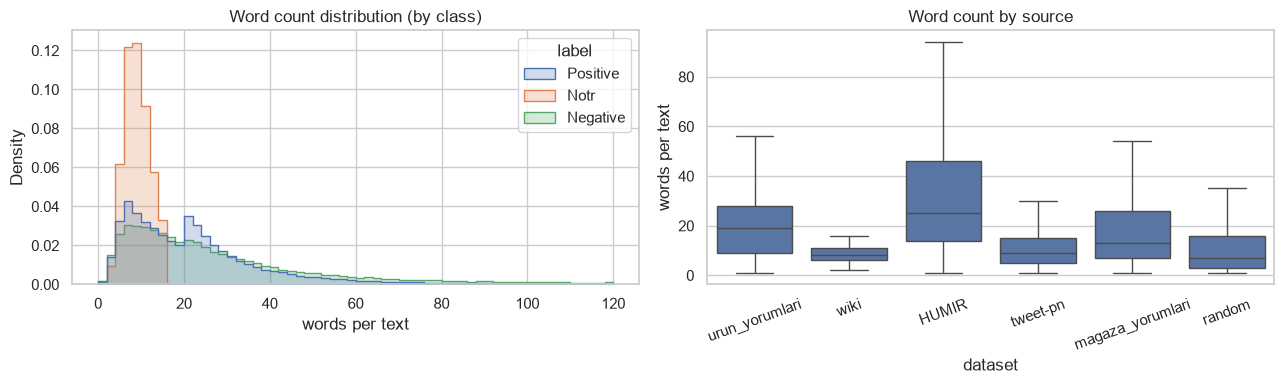

In [5]:
train['n_chars'] = train['text'].str.len()
train['n_words'] = train['text'].str.split().str.len()
print(train.groupby('label')[['n_chars', 'n_words']].describe().round(1).T)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=train, x='n_words', hue='label', bins=60, binrange=(0, 120), element='step', stat='density', common_norm=False, ax=ax[0])
ax[0].set_title('Word count distribution (by class)'); ax[0].set_xlabel('words per text')
sns.boxplot(data=train, x='dataset', y='n_words', showfliers=False, ax=ax[1]); ax[1].set_title('Word count by source')
ax[1].set_ylabel('words per text'); ax[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

In [6]:
from transformers import AutoTokenizer
from src.config import BERT_NAME, MAX_LENGTH
tok = AutoTokenizer.from_pretrained(BERT_NAME)
s = train.sample(3000, random_state=0)
n_tok = s['text'].map(lambda t: len(tok(t)['input_ids']))
print(n_tok.describe().round(1))
print(f'Share of texts longer than {MAX_LENGTH} tokens: {100*(n_tok > MAX_LENGTH).mean():.2f}%')
# 'Shipping was very late, I wasn't satisfied at all.'
print('Example tokenization:', tok.tokenize('Kargo çok geç geldi, hiç memnun kalmadım.'))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (535 > 512). Running this sequence through the model will result in indexing errors


count    3000.0
mean       31.9
std        43.2
min         3.0
25%        12.0
50%        18.0
75%        37.0
max       808.0
Name: text, dtype: float64
Share of texts longer than 128 tokens: 2.60%
Example tokenization: ['Kargo', 'çok', 'geç', 'geldi', ',', 'hiç', 'memnun', 'kalmadı', '##m', '.']


BERTurk uses a sub-word (WordPiece) tokenizer: words it doesn't know as a whole are split into pieces starting with `##`. This lets the model learn Turkish suffixes as meaningful units (e.g. `kalmadım` → `kalmadı` + `##m`, where `##m` is the first-person suffix: "didn't remain" + "I").

## 4. Duplicates and leakage check

In [7]:
print('Duplicate texts in train:', raw_train['text'].duplicated().sum())
overlap = set(train['text']) & set(test['text'])
print('Texts appearing in both train and test:', len(overlap))
print('-> src/data.py removes these texts from the test set.')

Duplicate texts in train: 621


Texts appearing in both train and test: 245
-> src/data.py removes these texts from the test set.


## 5. Working subset
The small stratified subset created by `src/data.py`:

In [8]:
from src.data import load_splits
tr, va, te = load_splits()
pd.DataFrame({n: d['label'].value_counts() for n, d in [('train', tr), ('val', va), ('test', te)]})

,train,val,test
label,,,
Positive,2140,267,534
Notr,1400,175,351
Negative,460,58,115


## Summary
- The classes are imbalanced (Negative ≈ 11.5%) → we use **macro F1** and `class_weight='balanced'` in the baseline.
- Labels are strongly tied to the source (`dataset`) → watch out for shortcut learning.
- The vast majority of texts are under 128 tokens → `max_length=128` is enough.
- Train–test overlaps were removed → leakage-free evaluation.